# FAST-LIVO2 rosbag accumulated LiDAR projection check

This notebook reads an image frame from a ROS1 bag, accumulates many LiDAR frames using odometry poses, and projects the accumulated cloud into the selected image.

Expected pose convention from FAST-LIVO2:

- `/aft_mapped_to_init_lidar`: LiDAR pose in `camera_init` / world frame
- `/aft_mapped_to_init_cam`: camera pose in `camera_init` / world frame, if available
- If camera pose is not available, the notebook derives camera pose from LiDAR pose and `Rcl/Pcl`.

In [8]:
# If needed:
# %pip install -r requirements.txt

In [9]:
from pathlib import Path
import bisect
import numpy as np
import cv2
import yaml
import matplotlib.pyplot as plt
from rosbags.highlevel import AnyReader

ROOT = Path.cwd()

# Change this to your local bag path.
BAG_PATH = Path(r"D:/datasets/iae/rosbag/5f/map_sync.bag")

IMAGE_TOPIC = "/origin_img"
LIDAR_TOPIC = "/cloud_registered_body"
POSE_TOPIC = "/aft_mapped_to_init"

# Image frame to inspect.
IMAGE_INDEX = 0

CAMERA_YAML = ROOT / "config" / "camera_iae.yaml"
EXTRINSIC_YAML = ROOT / "config" / "iae.yaml"

# Accumulation controls. Start conservative, then increase.
ACCUMULATE_ALL_LIDAR_FRAMES = True
MAX_LIDAR_FRAMES = 300          # used only if ACCUMULATE_ALL_LIDAR_FRAMES is False
TIME_WINDOW_SEC = 30.0          # +/- around selected image, used only if ACCUMULATE_ALL_LIDAR_FRAMES is False
MAX_POINTS_PER_SCAN = None      # None means keep every point in each scan
MAX_ACCUM_POINTS = None         # None means keep the full accumulated cloud

# Projection controls.
MIN_DEPTH_M = 0.2
MAX_DEPTH_M = 80.0
MAX_POINTS_TO_DRAW = 400_000

print("bag exists:", BAG_PATH.exists(), BAG_PATH)

bag exists: True D:\datasets\iae\rosbag\5f\map_sync.bag


In [10]:
def get_bag_topic_info(bag_path):
    rows = []
    with AnyReader([Path(bag_path)]) as reader:
        for c in reader.connections:
            rows.append((c.topic, c.msgtype, getattr(c, "msgcount", "?")))
    return sorted(rows, key=lambda x: x[0])

topic_info = get_bag_topic_info(BAG_PATH)

print("=== BAG TOPICS ===")
for topic, msgtype, count in topic_info:
    print(f"{topic:45s} {msgtype:40s} count={count}")

print("\n=== LIKELY TOPIC CANDIDATES ===")
keywords = ("image", "camera", "ouster", "points", "imu", "odom", "mapped", "tf")
for topic, msgtype, count in topic_info:
    if any(k in topic.lower() or k in msgtype.lower() for k in keywords):
        print(f"{topic:45s} {msgtype:40s} count={count}")

available_topics = {topic for topic, _, _ in topic_info}
print("\n=== CONFIGURED TOPICS ===")
for name, topic in {
    "IMAGE_TOPIC": IMAGE_TOPIC,
    "LIDAR_TOPIC": LIDAR_TOPIC,
    "POSE_TOPIC": POSE_TOPIC,
}.items():
    if topic is None:
        print(f"{name:18s}: None")
    else:
        print(f"{name:18s}: {topic:35s} exists={topic in available_topics}")


=== BAG TOPICS ===
/aft_mapped_to_init                           nav_msgs/msg/Odometry                    count=2952
/cloud_registered_body                        sensor_msgs/msg/PointCloud2              count=1476
/origin_img                                   sensor_msgs/msg/Image                    count=1476
/path                                         nav_msgs/msg/Path                        count=1476
/tf                                           tf2_msgs/msg/TFMessage                   count=5896

=== LIKELY TOPIC CANDIDATES ===
/aft_mapped_to_init                           nav_msgs/msg/Odometry                    count=2952
/origin_img                                   sensor_msgs/msg/Image                    count=1476
/tf                                           tf2_msgs/msg/TFMessage                   count=5896

=== CONFIGURED TOPICS ===
IMAGE_TOPIC       : /origin_img                         exists=True
LIDAR_TOPIC       : /cloud_registered_body              exists=True
P

In [11]:
def load_yaml(path):
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        return yaml.safe_load(f)

cam_cfg = load_yaml(CAMERA_YAML)
iae_cfg = load_yaml(EXTRINSIC_YAML)

fx = float(cam_cfg["cam_fx"])
fy = float(cam_cfg["cam_fy"])
cx = float(cam_cfg["cam_cx"])
cy = float(cam_cfg["cam_cy"])
scale = float(cam_cfg.get("scale", 1.0))
model_w = int(float(cam_cfg["cam_width"]) * scale)
model_h = int(float(cam_cfg["cam_height"]) * scale)

K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float64)
Rcl = np.array(iae_cfg["extrin_calib"]["Rcl"], dtype=np.float64).reshape(3, 3)
Pcl = np.array(iae_cfg["extrin_calib"]["Pcl"], dtype=np.float64).reshape(3)

print("camera model:", model_w, model_h)
print("K:\n", K)
print("Rcl:\n", Rcl)
print("Pcl:", Pcl)

camera model: 1280 720
K:
 [[580.9368695    0.         599.83744741]
 [  0.         580.87620786 327.77562569]
 [  0.           0.           1.        ]]
Rcl:
 [[-0.00428133 -0.99998031 -0.00458851]
 [ 0.03408967  0.00443993 -0.99940892]
 [ 0.99940961 -0.00443522  0.03406999]]
Pcl: [ 0.01900277 -0.08567301 -0.1253142 ]


In [12]:
def msg_stamp_sec(msg):
    return float(msg.header.stamp.sec) + float(msg.header.stamp.nanosec) * 1e-9

def quat_xyzw_to_R(q):
    x, y, z, w = float(q.x), float(q.y), float(q.z), float(q.w)
    n = x*x + y*y + z*z + w*w
    if n < 1e-12:
        return np.eye(3)
    s = 2.0 / n
    xx, yy, zz = x*x*s, y*y*s, z*z*s
    xy, xz, yz = x*y*s, x*z*s, y*z*s
    wx, wy, wz = w*x*s, w*y*s, w*z*s
    return np.array([
        [1.0 - (yy + zz), xy - wz, xz + wy],
        [xy + wz, 1.0 - (xx + zz), yz - wx],
        [xz - wy, yz + wx, 1.0 - (xx + yy)],
    ], dtype=np.float64)

def pose_msg_to_T_world_body(msg):
    p = msg.pose.pose.position
    q = msg.pose.pose.orientation
    R_wb = quat_xyzw_to_R(q)
    t_wb = np.array([p.x, p.y, p.z], dtype=np.float64)
    return R_wb, t_wb

def print_bag_topics(bag_path):
    with AnyReader([Path(bag_path)]) as reader:
        for c in reader.connections:
            print(f"{c.topic:45s} {c.msgtype}")

print_bag_topics(BAG_PATH)

/cloud_registered_body                        sensor_msgs/msg/PointCloud2
/aft_mapped_to_init                           nav_msgs/msg/Odometry
/path                                         nav_msgs/msg/Path
/origin_img                                   sensor_msgs/msg/Image
/tf                                           tf2_msgs/msg/TFMessage


In [13]:
def read_pose_series(bag_path, topic):
    times = []
    rotations = []
    translations = []
    with AnyReader([Path(bag_path)]) as reader:
        conns = [c for c in reader.connections if c.topic == topic]
        if not conns:
            return np.array([]), [], []
        for conn, t, rawdata in reader.messages(connections=conns):
            msg = reader.deserialize(rawdata, conn.msgtype)
            stamp = msg_stamp_sec(msg)
            R, trans = pose_msg_to_T_world_body(msg)
            times.append(stamp)
            rotations.append(R)
            translations.append(trans)
    order = np.argsort(times)
    return np.asarray(times)[order], [rotations[i] for i in order], [translations[i] for i in order]

def nearest_pose(times, rotations, translations, target_time):
    if len(times) == 0:
        raise ValueError("empty pose series")
    i = bisect.bisect_left(times, target_time)
    candidates = []
    if i < len(times):
        candidates.append(i)
    if i > 0:
        candidates.append(i - 1)
    best = min(candidates, key=lambda j: abs(times[j] - target_time))
    return rotations[best], translations[best], float(times[best]), float(times[best] - target_time)

pose_times, pose_R, pose_t = read_pose_series(BAG_PATH, POSE_TOPIC)
print("poses:", len(pose_times), POSE_TOPIC)
if len(pose_times):
    print("pose time range:", pose_times[0], pose_times[-1])

poses: 2952 /aft_mapped_to_init
pose time range: 1775613208.87194 1775613364.7519379


image index: 0
image stamp: 1775613208.87194
image bag time: 1783569579.8326974
image size: 1280 720


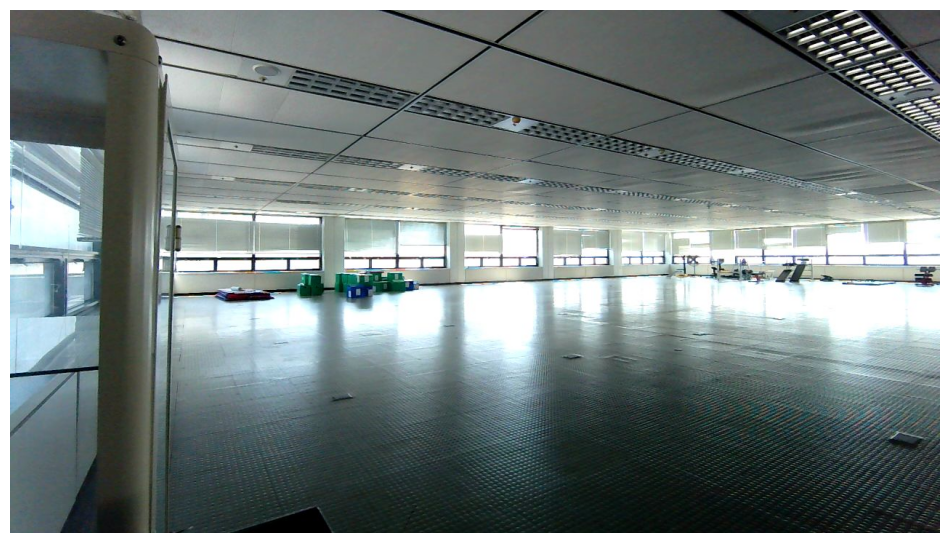

In [14]:
def image_msg_to_rgb(msg):
    if hasattr(msg, "format") and not hasattr(msg, "height"):
        img_bgr = cv2.imdecode(np.frombuffer(bytes(msg.data), dtype=np.uint8), cv2.IMREAD_COLOR)
        if img_bgr is None:
            raise RuntimeError("compressed image decode failed")
        return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    h, w = int(msg.height), int(msg.width)
    enc = str(msg.encoding).lower()
    data = np.frombuffer(bytes(msg.data), dtype=np.uint8)
    if enc in ("bgr8", "rgb8"):
        img = data.reshape(h, int(msg.step) // 3, 3)[:, :w, :]
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if enc == "bgr8" else img
    if enc in ("mono8", "8uc1"):
        img = data.reshape(h, int(msg.step))[:, :w]
        return cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    if enc in ("bgra8", "rgba8"):
        img = data.reshape(h, int(msg.step) // 4, 4)[:, :w, :]
        code = cv2.COLOR_BGRA2RGB if enc == "bgra8" else cv2.COLOR_RGBA2RGB
        return cv2.cvtColor(img, code)
    raise NotImplementedError(f"Unsupported image encoding: {msg.encoding}")
def get_message_by_index(bag_path, topic, index):
    with AnyReader([Path(bag_path)]) as reader:
        conns = [c for c in reader.connections if c.topic == topic]
        if not conns:
            raise ValueError(f"topic not found: {topic}")
        for i, (conn, t, rawdata) in enumerate(reader.messages(connections=conns)):
            if i == index:
                return reader.deserialize(rawdata, conn.msgtype), t * 1e-9
    raise IndexError(f"topic {topic} has fewer than {index + 1} messages")

image_msg, image_bag_time = get_message_by_index(BAG_PATH, IMAGE_TOPIC, IMAGE_INDEX)
image_stamp = msg_stamp_sec(image_msg)
image_rgb = image_msg_to_rgb(image_msg)

img_h, img_w = image_rgb.shape[:2]

print("image index:", IMAGE_INDEX)
print("image stamp:", image_stamp)
print("image bag time:", image_bag_time)
print("image size:", img_w, img_h)

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.axis("off");

In [15]:
POINT_FIELD_DTYPES = {
    1: np.int8,
    2: np.uint8,
    3: np.int16,
    4: np.uint16,
    5: np.int32,
    6: np.uint32,
    7: np.float32,
    8: np.float64,
}

def pointcloud2_to_xyz(msg):
    dtype_fields = []
    cursor = 0
    for f in sorted(msg.fields, key=lambda field: field.offset):
        if f.offset > cursor:
            dtype_fields.append((f"__pad{cursor}", np.uint8, f.offset - cursor))
            cursor = f.offset
        base = POINT_FIELD_DTYPES[int(f.datatype)]
        count = int(f.count)
        if count == 1:
            dtype_fields.append((f.name, base))
            cursor += np.dtype(base).itemsize
        else:
            dtype_fields.append((f.name, base, count))
            cursor += np.dtype(base).itemsize * count
    if msg.point_step > cursor:
        dtype_fields.append((f"__pad{cursor}", np.uint8, msg.point_step - cursor))

    dtype = np.dtype(dtype_fields)
    data = np.frombuffer(bytes(msg.data), dtype=dtype, count=int(msg.width) * int(msg.height))
    xyz = np.column_stack([data["x"], data["y"], data["z"]]).astype(np.float64)
    return xyz[np.isfinite(xyz).all(axis=1)]

def maybe_sample(points, max_points, seed=0):
    if max_points is None or len(points) <= max_points:
        return points
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(points), max_points, replace=False)
    return points[idx]

## Parser-style timestamp matching

This section follows the attached C++ parser rule:

- read one pose topic plus one color topic plus one depth/LiDAR topic
- keep previous and next pose messages
- for each pending color/depth message, compare timestamp delta to previous and next pose
- accept only when `min(delta_prev, delta_next) < 0.01`
- compute `T_W_C = T_W_B @ T_B_C` for images and `T_W_L = T_W_B @ T_B_L` for LiDAR clouds

In [16]:
PARSER_POSE_TOPIC = "/aft_mapped_to_init"
PARSER_COLOR_TOPIC = "/origin_img"
PARSER_DEPTH_TOPIC = "/cloud_registered_body"
PARSER_MAX_DELTA_SEC = 0.01

Rbl = np.array(iae_cfg["extrin_calib"]["extrinsic_R"], dtype=np.float64).reshape(3, 3)
tbl = np.array(iae_cfg["extrin_calib"]["extrinsic_T"], dtype=np.float64).reshape(3)

T_B_L = np.eye(4, dtype=np.float64)
T_B_L[:3, :3] = Rbl
T_B_L[:3, 3] = tbl

T_C_L = np.eye(4, dtype=np.float64)
T_C_L[:3, :3] = Rcl
T_C_L[:3, 3] = Pcl

T_B_C = T_B_L @ np.linalg.inv(T_C_L)

print("T_B_L:\n", T_B_L)
print("T_C_L:\n", T_C_L)
print("T_B_C = T_B_L @ inv(T_C_L):\n", T_B_C)


T_B_L:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
T_C_L:
 [[-0.00428133 -0.99998031 -0.00458851  0.01900277]
 [ 0.03408967  0.00443993 -0.99940892 -0.08567301]
 [ 0.99940961 -0.00443522  0.03406999 -0.1253142 ]
 [ 0.          0.          0.          1.        ]]
T_B_C = T_B_L @ inv(T_C_L):
 [[-0.00428133  0.03408967  0.99940961  0.12824214]
 [-0.99998031  0.00443994 -0.00443522  0.01882698]
 [-0.0045885  -0.99940891  0.03406999 -0.08126572]
 [ 0.          0.          0.          1.        ]]


In [17]:
def T_from_odom_msg(msg):
    R, t = pose_msg_to_T_world_body(msg)
    T = np.eye(4, dtype=np.float64)
    T[:3, :3] = R
    T[:3, 3] = t
    return T

def image_msg_to_rgb(msg):
    msgtype = type(msg).__name__.lower()
    if hasattr(msg, "format") and not hasattr(msg, "height"):
        img_bgr = cv2.imdecode(np.frombuffer(bytes(msg.data), dtype=np.uint8), cv2.IMREAD_COLOR)
        if img_bgr is None:
            raise RuntimeError("compressed image decode failed")
        return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    h, w = int(msg.height), int(msg.width)
    enc = str(msg.encoding).lower()
    data = np.frombuffer(bytes(msg.data), dtype=np.uint8)
    if enc in ("bgr8", "rgb8"):
        img = data.reshape(h, int(msg.step) // 3, 3)[:, :w, :]
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if enc == "bgr8" else img
    if enc in ("mono8", "8uc1"):
        img = data.reshape(h, int(msg.step))[:, :w]
        return cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    if enc in ("bgra8", "rgba8"):
        img = data.reshape(h, int(msg.step) // 4, 4)[:, :w, :]
        code = cv2.COLOR_BGRA2RGB if enc == "bgra8" else cv2.COLOR_RGBA2RGB
        return cv2.cvtColor(img, code)
    raise NotImplementedError(f"Unsupported image encoding: {msg.encoding}")

def choose_nearest_pose_pair(prev_pose, next_pose, target_stamp, max_delta=PARSER_MAX_DELTA_SEC):
    if prev_pose is None or next_pose is None:
        return None, None
    prev_msg, prev_stamp = prev_pose
    next_msg, next_stamp = next_pose
    delta_prev = abs(prev_stamp - target_stamp)
    delta_next = abs(next_stamp - target_stamp)
    min_delta = min(delta_prev, delta_next)
    if min_delta >= max_delta:
        return None, min_delta
    return (prev_msg if delta_prev < delta_next else next_msg), min_delta


In [18]:
def build_matched_dataset_like_parser(max_depth_frames=None):
    pose_prev = None
    pose_next = None
    pending_color = None
    pending_depth = None

    colors = []
    depths = []
    depth_world_chunks = []
    rejected_color = 0
    rejected_depth = 0

    topics = [PARSER_POSE_TOPIC, PARSER_COLOR_TOPIC, PARSER_DEPTH_TOPIC]
    with AnyReader([Path(BAG_PATH)]) as reader:
        conns = [c for c in reader.connections if c.topic in topics]
        if not conns:
            raise ValueError("No parser topics found in bag")

        for conn, bag_t, rawdata in reader.messages(connections=conns):
            msg = reader.deserialize(rawdata, conn.msgtype)
            topic = conn.topic

            if topic == PARSER_POSE_TOPIC:
                pose_prev = pose_next
                pose_next = (msg, msg_stamp_sec(msg))
                if pose_prev is None:
                    continue

                if pending_color is not None:
                    color_msg, color_stamp = pending_color
                    nearest_pose, min_delta = choose_nearest_pose_pair(pose_prev, pose_next, color_stamp)
                    if nearest_pose is not None:
                        T_W_B = T_from_odom_msg(nearest_pose)
                        T_W_C = T_W_B @ T_B_C
                        colors.append({"msg": color_msg, "stamp": color_stamp, "T_W_C": T_W_C, "pose_stamp": msg_stamp_sec(nearest_pose), "delta": min_delta})
                        pending_color = None
                    elif min_delta is not None:
                        rejected_color += 1

                if pending_depth is not None:
                    depth_msg, depth_stamp = pending_depth
                    nearest_pose, min_delta = choose_nearest_pose_pair(pose_prev, pose_next, depth_stamp)
                    if nearest_pose is not None:
                        T_W_B = T_from_odom_msg(nearest_pose)
                        T_W_L = T_W_B @ T_B_L
                        pts_lidar = pointcloud2_to_xyz(depth_msg)
                        pts_world = (T_W_L[:3, :3] @ pts_lidar.T).T + T_W_L[:3, 3].reshape(1, 3)
                        depths.append({"stamp": depth_stamp, "T_W_L": T_W_L, "pose_stamp": msg_stamp_sec(nearest_pose), "delta": min_delta, "n": len(pts_lidar)})
                        depth_world_chunks.append(pts_world.astype(np.float32))
                        pending_depth = None
                        if max_depth_frames is not None and len(depths) >= max_depth_frames:
                            break
                    elif min_delta is not None:
                        rejected_depth += 1

            elif topic == PARSER_COLOR_TOPIC:
                pending_color = (msg, msg_stamp_sec(msg))

            elif topic == PARSER_DEPTH_TOPIC:
                pending_depth = (msg, msg_stamp_sec(msg))

    if not depth_world_chunks:
        raise RuntimeError("No depth/LiDAR frames matched with parser delta rule")

    points_world_parser = np.vstack(depth_world_chunks)
    print("matched colors:", len(colors), "rejected_color_checks:", rejected_color)
    print("matched depth frames:", len(depths), "rejected_depth_checks:", rejected_depth)
    print("accumulated parser points:", points_world_parser.shape)
    if colors:
        print("color delta max:", max(c["delta"] for c in colors))
    if depths:
        print("depth delta max:", max(d["delta"] for d in depths))
    return colors, depths, points_world_parser

parser_colors, parser_depths, parser_points_world = build_matched_dataset_like_parser(max_depth_frames=None)


matched colors: 1470 rejected_color_checks: 4
matched depth frames: 1476 rejected_depth_checks: 0
accumulated parser points: (23047933, 3)
color delta max: 0.0
depth delta max: 0.0


In [19]:
def project_parser_image_index(image_index, save=True, show=True, max_points=MAX_POINTS_TO_DRAW):
    entry = parser_colors[image_index]
    image_rgb_local = image_msg_to_rgb(entry["msg"])
    img_h_local, img_w_local = image_rgb_local.shape[:2]
    pts = maybe_sample(parser_points_world, max_points, seed=image_index)
    R_wc = entry["T_W_C"][:3, :3]
    t_wc = entry["T_W_C"][:3, 3]
    uv_local, depth_local = project_world_to_image(pts, R_wc, t_wc, K, (img_w_local, img_h_local))

    print("parser image index:", image_index)
    print("image stamp:", entry["stamp"], "pose stamp:", entry["pose_stamp"], "delta:", entry["delta"])
    print("image size:", img_w_local, img_h_local)
    print("projected visible points:", len(uv_local))

    fig = plt.figure(figsize=(14, 8))
    plt.imshow(image_rgb_local)
    if len(uv_local):
        order = np.argsort(depth_local)[::-1]
        uv_draw = uv_local[order]
        depth_draw = depth_local[order]
        vmax = min(MAX_DEPTH_M, np.percentile(depth_draw, 98))
        sc = plt.scatter(uv_draw[:, 0], uv_draw[:, 1], c=depth_draw, s=1.0, cmap="turbo", alpha=0.75, vmin=MIN_DEPTH_M, vmax=vmax)
        plt.colorbar(sc, label="camera depth z [m]")
    plt.title(f"Parser-matched accumulated LiDAR projected to origin_img[{image_index}] | visible={len(uv_local)}")
    plt.xlim(0, img_w_local)
    plt.ylim(img_h_local, 0)
    plt.axis("off")

    out_path = None
    if save:
        out_path = ROOT / "frames" / f"parser_matched_projection_{image_index:04d}.png"
        fig.savefig(out_path, dpi=160, bbox_inches="tight", pad_inches=0)
        print("saved:", out_path)
    if not show:
        plt.close(fig)
    return {"image_index": image_index, "visible_points": len(uv_local), "out_path": out_path}

# Example:
# project_parser_image_index(0)


In [20]:
def accumulate_lidar_world_points(bag_path):
    if len(pose_times) == 0:
        raise ValueError(f"No poses found on {POSE_TOPIC}. Record FAST-LIVO2 odometry topics first.")

    chunks = []
    scan_count = 0
    point_count = 0
    pose_dt_values = []

    with AnyReader([Path(bag_path)]) as reader:
        conns = [c for c in reader.connections if c.topic == LIDAR_TOPIC]
        if not conns:
            raise ValueError(f"topic not found: {LIDAR_TOPIC}")

        for conn, bag_t, rawdata in reader.messages(connections=conns):
            msg = reader.deserialize(rawdata, conn.msgtype)
            stamp = msg_stamp_sec(msg)

            if not ACCUMULATE_ALL_LIDAR_FRAMES:
                if abs(stamp - image_stamp) > TIME_WINDOW_SEC:
                    continue
                if scan_count >= MAX_LIDAR_FRAMES:
                    break

            R_wb, t_wb, pose_time, pose_dt = nearest_pose(pose_times, pose_R, pose_t, stamp)
            T_W_B = np.eye(4, dtype=np.float64)
            T_W_B[:3, :3] = R_wb
            T_W_B[:3, 3] = t_wb
            T_W_L = T_W_B @ T_B_L
            pose_dt_values.append(pose_dt)

            points_lidar = pointcloud2_to_xyz(msg)
            points_lidar = maybe_sample(points_lidar, MAX_POINTS_PER_SCAN, seed=scan_count)
            points_world = (T_W_L[:3, :3] @ points_lidar.T).T + T_W_L[:3, 3].reshape(1, 3)
            chunks.append(points_world.astype(np.float32))

            scan_count += 1
            point_count += len(points_world)
            if MAX_ACCUM_POINTS is not None and point_count >= MAX_ACCUM_POINTS:
                break

    if not chunks:
        raise RuntimeError("No LiDAR frames accumulated")

    points_world = np.vstack(chunks)
    points_world = maybe_sample(points_world, MAX_ACCUM_POINTS, seed=42)
    return points_world, scan_count, np.asarray(pose_dt_values)

points_world, num_scans, pose_dt_values = accumulate_lidar_world_points(BAG_PATH)
print("accumulated scans:", num_scans)
print("accumulated points:", points_world.shape)
print("pose dt mean/max abs:", float(np.mean(np.abs(pose_dt_values))), float(np.max(np.abs(pose_dt_values))))
print("world min:", points_world.min(axis=0))
print("world max:", points_world.max(axis=0))

accumulated scans: 1476
accumulated points: (23047933, 3)
pose dt mean/max abs: 0.0 0.0
world min: [-178.42493   -85.20944   -72.341896]
world max: [122.743645 118.58761   23.40874 ]


In [21]:
# Camera pose at selected image timestamp.
R_wb_img, t_wb_img, pose_time, pose_dt = nearest_pose(pose_times, pose_R, pose_t, image_stamp)
T_W_B_img = np.eye(4, dtype=np.float64)
T_W_B_img[:3, :3] = R_wb_img
T_W_B_img[:3, 3] = t_wb_img
T_W_C_img = T_W_B_img @ T_B_C
R_wc = T_W_C_img[:3, :3]
t_wc = T_W_C_img[:3, 3]
print("derived camera pose from single pose topic + T_B_C:", POSE_TOPIC)

print("selected pose time:", pose_time)
print("selected pose dt [s]:", pose_dt)
print("R_wc:\n", R_wc)
print("t_wc:", t_wc)

derived camera pose from single pose topic + T_B_C: /aft_mapped_to_init
selected pose time: 1775613208.87194
selected pose dt [s]: 0.0
R_wc:
 [[-0.00445418  0.03207526  0.99947553]
 [-0.99998242  0.00376859 -0.00457738]
 [-0.00391343 -0.99947835  0.03205791]]
t_wc: [ 0.12751806  0.01755975 -0.08355643]


In [22]:
def project_world_to_image(points_world, R_wc, t_wc, K, image_size):
    img_w, img_h = image_size
    points_cam = (R_wc.T @ (points_world.astype(np.float64) - t_wc.reshape(1, 3)).T).T
    z = points_cam[:, 2]
    mask = (z > MIN_DEPTH_M) & (z < MAX_DEPTH_M) & np.isfinite(z)
    points_cam = points_cam[mask]
    z = z[mask]

    uvw = (K @ points_cam.T).T
    uv = uvw[:, :2] / uvw[:, 2:3]
    u, v = uv[:, 0], uv[:, 1]
    inside = (u >= 0) & (u < img_w) & (v >= 0) & (v < img_h)
    return uv[inside], z[inside]

points_for_projection = maybe_sample(points_world, MAX_POINTS_TO_DRAW, seed=7)
uv, depth = project_world_to_image(points_for_projection, R_wc, t_wc, K, (img_w, img_h))
print("projected visible points:", len(uv))
if len(depth):
    print("depth min/max:", float(depth.min()), float(depth.max()))

projected visible points: 117102
depth min/max: 0.3145828162964139 38.23931436851901


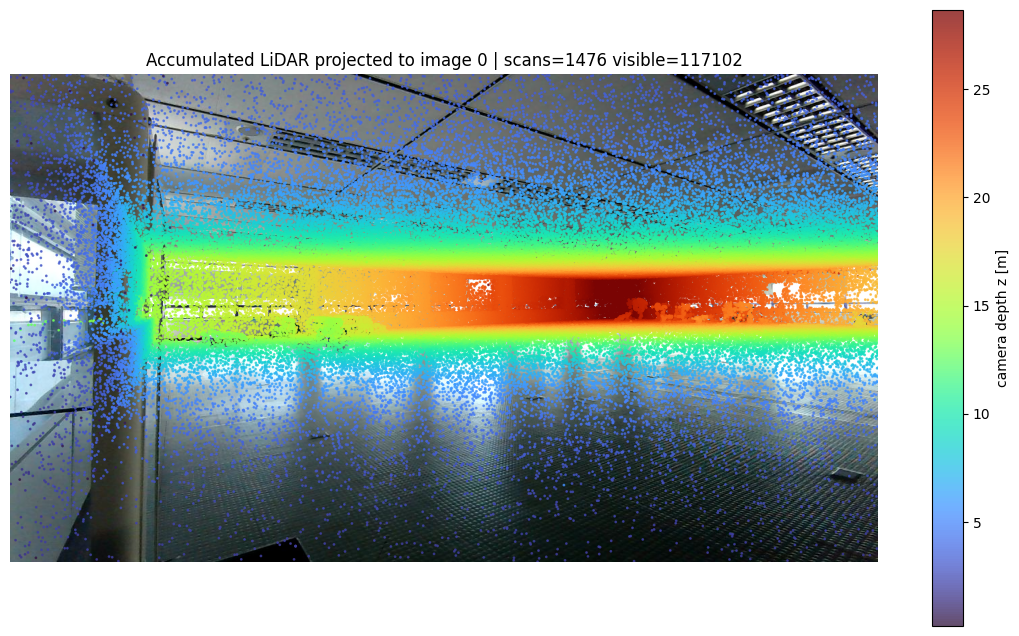

In [23]:
plt.figure(figsize=(14, 8))
plt.imshow(image_rgb)

if len(uv):
    order = np.argsort(depth)[::-1]
    uv_draw = uv[order]
    depth_draw = depth[order]
    vmax = min(MAX_DEPTH_M, np.percentile(depth_draw, 98))
    sc = plt.scatter(uv_draw[:, 0], uv_draw[:, 1], c=depth_draw, s=1.0, cmap="turbo", alpha=0.75, vmin=MIN_DEPTH_M, vmax=vmax)
    plt.colorbar(sc, label="camera depth z [m]")

plt.title(f"Accumulated LiDAR projected to image {IMAGE_INDEX} | scans={num_scans} visible={len(uv)}")
plt.xlim(0, img_w)
plt.ylim(img_h, 0)
plt.axis("off");

In [25]:
def visualize_accumulated_o3d(image_index=IMAGE_INDEX, max_points=500_000, show_lidar_poses=True, pose_stride=20):
    import open3d as o3d

    image_msg, _ = get_message_by_index(BAG_PATH, IMAGE_TOPIC, image_index)
    image_stamp = msg_stamp_sec(image_msg)

    R_wb_img, t_wb_img, pose_time, pose_dt = nearest_pose(pose_times, pose_R, pose_t, image_stamp)
    T_W_B_img = np.eye(4, dtype=np.float64)
    T_W_B_img[:3, :3] = R_wb_img
    T_W_B_img[:3, 3] = t_wb_img
    T_W_C_img = T_W_B_img @ T_B_C
    R_wc = T_W_C_img[:3, :3]
    t_wc = T_W_C_img[:3, 3]
    pose_source = f"{POSE_TOPIC} + T_B_C"

    pts = maybe_sample(points_world, max_points, seed=image_index).astype(np.float64)
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(pts)

    z = pts[:, 2]
    z_norm = (z - np.percentile(z, 2)) / max(1e-6, np.percentile(z, 98) - np.percentile(z, 2))
    z_norm = np.clip(z_norm, 0.0, 1.0)
    pcd.colors = o3d.utility.Vector3dVector(plt.get_cmap("turbo")(z_norm)[:, :3])

    world_frame = o3d.geometry.TriangleMesh.create_coordinate_frame(size=2.0, origin=[0, 0, 0])

    T_wc = np.eye(4)
    T_wc[:3, :3] = R_wc
    T_wc[:3, 3] = t_wc
    camera_frame = o3d.geometry.TriangleMesh.create_coordinate_frame(size=1.0)
    camera_frame.transform(T_wc)

    geoms = [pcd, world_frame, camera_frame]

    if show_lidar_poses and len(pose_times):
        for i in range(0, len(pose_times), max(1, pose_stride)):
            T = np.eye(4)
            T[:3, :3] = pose_R[i]
            T[:3, 3] = pose_t[i]
            T = T @ T_B_L
            frame = o3d.geometry.TriangleMesh.create_coordinate_frame(size=0.35)
            frame.transform(T)
            geoms.append(frame)

    print("O3D points:", len(pts))
    print("image index:", image_index, "image stamp:", image_stamp)
    print("camera pose source:", pose_source)
    print("camera pose time/dt:", pose_time, pose_dt)
    print("controls: left drag rotate, wheel zoom, right drag pan")
    o3d.visualization.draw_geometries(geoms, window_name=f"Accumulated LiDAR + camera image {image_index}")

# Example:
visualize_accumulated_o3d(IMAGE_INDEX)


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
O3D points: 500000
image index: 0 image stamp: 1775613208.87194
camera pose source: /aft_mapped_to_init + T_B_C
camera pose time/dt: 1775613208.87194 0.0
controls: left drag rotate, wheel zoom, right drag pan


image index: 1000
image stamp: 1775613314.659922
image bag time: 1783569860.0509293
pose source: /aft_mapped_to_init + T_B_C
pose time: 1775613314.659922 pose dt [s]: 0.0
image size: 1280 720
visible projected points: 16735
depth min/max: 1.5408008193721898 15.98537740585002
saved: d:\FAST-LIVO2\frames\rosbag_accum_projection_1000.png


{'image_index': 1000,
 'image_stamp': 1775613314.659922,
 'pose_time': 1775613314.659922,
 'pose_dt': 0.0,
 'visible_points': 16735,
 'out_path': WindowsPath('d:/FAST-LIVO2/frames/rosbag_accum_projection_1000.png')}

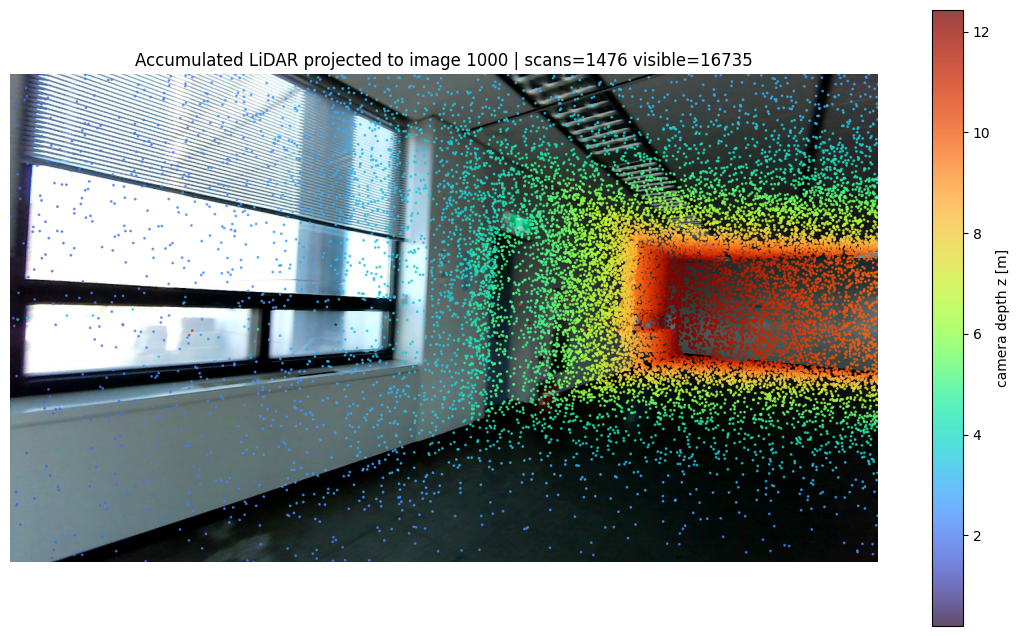

In [26]:
def project_image_index(image_index, save=True, show=True):
    image_msg, image_bag_time = get_message_by_index(BAG_PATH, IMAGE_TOPIC, image_index)
    image_stamp = msg_stamp_sec(image_msg)
    image_rgb = image_msg_to_rgb(image_msg)
    img_h, img_w = image_rgb.shape[:2]

    R_wb_img, t_wb_img, pose_time, pose_dt = nearest_pose(pose_times, pose_R, pose_t, image_stamp)
    T_W_B_img = np.eye(4, dtype=np.float64)
    T_W_B_img[:3, :3] = R_wb_img
    T_W_B_img[:3, 3] = t_wb_img
    T_W_C_img = T_W_B_img @ T_B_C
    R_wc = T_W_C_img[:3, :3]
    t_wc = T_W_C_img[:3, 3]
    pose_source = f"{POSE_TOPIC} + T_B_C"

    points_for_projection = maybe_sample(points_world, MAX_POINTS_TO_DRAW, seed=image_index)
    uv, depth = project_world_to_image(points_for_projection, R_wc, t_wc, K, (img_w, img_h))

    print("image index:", image_index)
    print("image stamp:", image_stamp)
    print("image bag time:", image_bag_time)
    print("pose source:", pose_source)
    print("pose time:", pose_time, "pose dt [s]:", pose_dt)
    print("image size:", img_w, img_h)
    print("visible projected points:", len(uv))
    if len(depth):
        print("depth min/max:", float(depth.min()), float(depth.max()))

    fig = plt.figure(figsize=(14, 8))
    plt.imshow(image_rgb)
    if len(uv):
        order = np.argsort(depth)[::-1]
        uv_draw = uv[order]
        depth_draw = depth[order]
        vmax = min(MAX_DEPTH_M, np.percentile(depth_draw, 98))
        sc = plt.scatter(uv_draw[:, 0], uv_draw[:, 1], c=depth_draw, s=1.0, cmap="turbo", alpha=0.75, vmin=MIN_DEPTH_M, vmax=vmax)
        plt.colorbar(sc, label="camera depth z [m]")
    plt.title(f"Accumulated LiDAR projected to image {image_index} | scans={num_scans} visible={len(uv)}")
    plt.xlim(0, img_w)
    plt.ylim(img_h, 0)
    plt.axis("off")

    out_path = None
    if save:
        out_path = ROOT / "frames" / f"rosbag_accum_projection_{image_index:04d}.png"
        fig.savefig(out_path, dpi=160, bbox_inches="tight", pad_inches=0)
        print("saved:", out_path)
    if not show:
        plt.close(fig)
    return {"image_index": image_index, "image_stamp": image_stamp, "pose_time": pose_time, "pose_dt": pose_dt, "visible_points": len(uv), "out_path": out_path}

IMAGE_INDEX = 1000

# Example:
result = project_image_index(IMAGE_INDEX)
result

In [ ]:
out_path = ROOT / "frames" / f"rosbag_accum_projection_{IMAGE_INDEX:04d}.png"
fig = plt.figure(figsize=(14, 8))
plt.imshow(image_rgb)
if len(uv):
    plt.scatter(uv[:, 0], uv[:, 1], c=depth, s=1.0, cmap="turbo", alpha=0.75)
plt.xlim(0, img_w)
plt.ylim(img_h, 0)
plt.axis("off")
plt.tight_layout(pad=0)
fig.savefig(out_path, dpi=160, bbox_inches="tight", pad_inches=0)
plt.close(fig)
print(out_path)